# 03 · Does SeatScore match what people choose?

**Question:** SeatScore ranks seats from room geometry: viewing angle, neck angle, centering, sound position, clearance over the head in front and aisle access. Do real viewers at Cinematheque KOFA pick seats in that order? And which weights describe their choices best?

**Data:** booked seats from notebook 01 (cancellations removed), with the Apr 2020 – Sep 2022 distancing window excluded. Layouts are from notebook 02.

**Scores** come from the web app's own TypeScript engine, called through `web/scripts/score.ts` (see `pipeline/engine.py`), so this analysis and the app always agree.

In [1]:
import copy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from pipeline.engine import BALANCED, FACTORS, frames
from pipeline.layouts import HALL1, HALL2
from pipeline.preference import EARLY_SHARE, grid_spearman, in_periods, seat_measures, spearman, split_half, weight_grid

INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

LAYOUT = {"hall1": HALL1, "hall2": HALL2}
NAME = {"hall1": "Hall 1", "hall2": "Hall 2"}
PRESETS = {  # same as web/src/engine/scoring.ts
    "Balanced": (BALANCED, None),
    "Picture first": (dict(immersion=5, neck=3, centering=4, sound=1, sightline=4, aisle=0), None),
    "Sound first": (dict(immersion=2, neck=2, centering=2, sound=5, sightline=2, aisle=0), None),
    "Front-row fan": (dict(immersion=5, neck=1, centering=2, sound=1, sightline=2, aisle=0), 60),
    "Easy exit": (dict(immersion=2, neck=2, centering=1, sound=1, sightline=2, aisle=5), None),
}

seats = pd.read_csv("../processed/kofa_seat_bookings.csv.gz", parse_dates=["showtime"])
normal = in_periods(seats)
measures = seat_measures(normal)
print(f"{len(normal):,} booked seats in {normal.groupby(['hall', 'showtime']).ngroups:,} screenings outside the distancing window")

380,252 booked seats in 3,865 screenings outside the distancing window


## 1. Measuring preference

A seat's overall booking rate mixes two things: how much people like it, and whether it was the last seat left in a sold-out show. The main measure here isolates choice:

* **Early-pick rate:** the share of screenings in which the seat was taken by one of the first {EARLY_SHARE:.0%} of that screening's bookings, when nearly every seat was still free.
* **Booking rate:** the share of screenings in which the seat was booked at all.
* **Booking order:** the average position when booked (0 = first booking, 1 = last). Lower means more wanted, so a good model correlates *negatively* with it.

All comparisons use **Spearman rank correlation** (ρ) across seats. It asks whether the model puts seats in the same order as the crowd, without assuming any particular scale. Wheelchair spaces are left out because they are booked for different reasons.

In [2]:
reliability = pd.DataFrame({"early-pick rate": split_half(normal, "early_rate"), "booking rate": split_half(normal, "booking_rate")})
reliability.index = reliability.index.map(NAME)
reliability.round(3)

,early-pick rate,booking rate
Hall 1,0.986,0.996
Hall 2,0.985,0.995


**The measures are very stable.** Splitting the screenings into two random halves gives almost the same seat ranking both times (ρ ≈ 0.99). So any gap between SeatScore and the crowd comes from the model, not from noise in the data. That 0.99 is the ceiling a perfect model could reach.

## 2. The presets as shipped

Each of the app's presets, scored on the notebook 02 layouts:

In [3]:
specs, keys = [], []
for hall, layout in LAYOUT.items():
    for name, (w, fov) in PRESETS.items():
        specs.append({"layout": layout, "weights": w, "target_fov": fov})
        keys.append((hall, name))
scored = dict(zip(keys, frames(specs)))

def standard(df):
    return df[df["kind"] == "standard"].set_index("seat_id")

rows = []
for (hall, name), df in scored.items():
    f = standard(df)
    m = measures[measures["hall"] == hall].set_index("seat_id").reindex(f.index)
    rows.append({"hall": NAME[hall], "preset": name, "early-pick rate": spearman(f["total"], m["early_rate"]),
                 "booking rate": spearman(f["total"], m["booking_rate"]), "booking order (lower = better)": spearman(f["total"], m["order_pct"])})
presets_table = pd.DataFrame(rows).set_index(["hall", "preset"]).round(2)
presets_table

early-pick rate  booking rate  \
hall   preset                                         
Hall 1 Balanced                  0.58          0.75   
       Picture first             0.55          0.71   
       Sound first               0.64          0.82   
       Front-row fan             0.56          0.65   
       Easy exit                 0.35          0.57   
Hall 2 Balanced                  0.73          0.75   
       Picture first             0.71          0.75   
       Sound first               0.73          0.71   
       Front-row fan             0.45          0.26   
       Easy exit                 0.36          0.41   

                      booking order (lower = better)  
hall   preset                                         
Hall 1 Balanced                                -0.16  
       Picture first                           -0.12  
       Sound first                             -0.21  
       Front-row fan                           -0.31  
       Easy exit                                0.06  
Hall 2 Balanced                                -0.60  
       Picture first                           -0.57  
       Sound first                             -0.65  
       Front-row fan                           -0.49  
       Easy exit                               -0.09

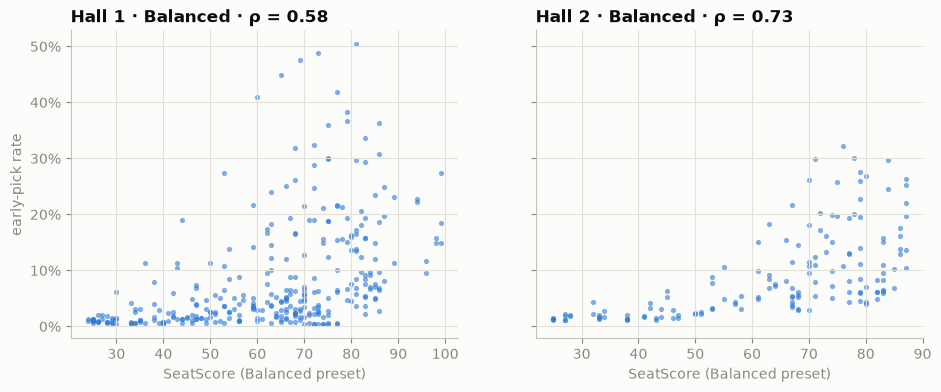

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, hall in zip(axes, LAYOUT):
    f = standard(scored[(hall, "Balanced")])
    m = measures[measures["hall"] == hall].set_index("seat_id").reindex(f.index)
    ax.scatter(f["total"], m["early_rate"], s=14, color=BLUE, alpha=0.6, linewidths=0)
    rho = spearman(f["total"], m["early_rate"])
    ax.set_title(f"{NAME[hall]} · Balanced · ρ = {rho:.2f}", loc="left")
    ax.set_xlabel("SeatScore (Balanced preset)")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].set_ylabel("early-pick rate")
plt.show()

**Balanced, the default, already ranks seats in roughly the crowd's order:** ρ ≈ 0.58 for early picks in Hall 1 and 0.73 in Hall 2, and 0.75 for overall booking rate in both halls. **Sound first** does a little better in Hall 1. **Easy exit** and **Front-row fan** do worst, so KOFA's audience is neither aisle-first nor close-up.

Booking order agrees in Hall 2 (ρ ≈ −0.6) but only weakly in Hall 1 (ρ ≈ −0.16). Early-pick rate is the cleaner signal of the three, and it's the one the rest of this notebook uses.

## 3. Which factors carry the signal?

Each factor on its own, against the early-pick rate (Balanced preset geometry, 40° target):

In [5]:
single = {}
for hall in LAYOUT:
    f = standard(scored[(hall, "Balanced")])
    m = measures[measures["hall"] == hall].set_index("seat_id").reindex(f.index)
    single[NAME[hall]] = {k: spearman(f[f"f_{k}"], m["early_rate"]) for k in FACTORS}
pd.DataFrame(single).round(2)

,Hall 1,Hall 2
immersion,0.29,0.63
neck,0.38,0.74
centering,0.60,0.46
sound,0.65,0.62
sightline,-0.13,-0.59
aisle,0.02,-0.03


In [6]:
f = standard(scored[("hall1", "Balanced")])
corr = f[[f"f_{k}" for k in FACTORS]].rank().corr()
corr.index = corr.columns = FACTORS
print("Hall 1: rank correlation between factor scores")
corr.round(2)

Hall 1: rank correlation between factor scores


,immersion,neck,centering,sound,sightline,aisle
immersion,1.00,0.88,0.44,0.44,-0.78,0.00
neck,0.88,1.00,0.41,0.50,-0.77,0.00
centering,0.44,0.41,1.00,0.86,-0.37,-0.20
sound,0.44,0.50,0.86,1.00,-0.28,-0.14
sightline,-0.78,-0.77,-0.37,-0.28,1.00,-0.01
aisle,0.00,0.00,-0.20,-0.14,-0.01,1.00


* **Centering, sound and neck comfort** each track the crowd well on their own.
* **Clear view runs the wrong way, especially in Hall 2.** The front row has nobody in front of it, so it gets a perfect clear-view score, but it's among the least-booked rows. Further back, the estimated 0.15 m rise per row gives less clearance, yet those rows are the most popular.
* **Aisle access is close to zero.** SeatScore counts wall-end seats as aisle seats, and those are the least-booked seats in both halls (notebook 02). The popular inner-aisle seats and the unpopular wall seats cancel out.
* **The factors overlap heavily.** Centering and sound move together (ρ ≈ 0.86), and so do immersion and neck comfort (0.88), with clear view running opposite to both. The data can't fully separate their weights, which matters for the next section.

## 4. Fitting the weights

SeatScore's sliders allow integer weights from 0 to 5 for each of the six factors: 46,655 combinations. Each one is tried at every target screen size from 30° to 64°, and the combination with the highest average early-pick ρ across both halls wins.

Fitting on the same data you report on flatters the result, so two **held-out tests** check it:

* **Time split:** fit on 2017 – Mar 2020, test on Oct 2022 – 2026.
* **Hall split:** fit on one hall, test on the other.

In [7]:
FOVS = list(range(30, 66, 2))
GRID = weight_grid()
fov_frames = frames([{"layout": LAYOUT[h], "target_fov": fov} for h in LAYOUT for fov in FOVS])
FACTOR_MATRIX = {}
i = 0
for hall in LAYOUT:
    for fov in FOVS:
        FACTOR_MATRIX[(hall, fov)] = standard(fov_frames[i]); i += 1

def target(meas, hall, index):
    return meas[meas["hall"] == hall].set_index("seat_id")["early_rate"].reindex(index).to_numpy()

def fit(meas, halls):
    best = None
    for fov in FOVS:
        rhos = np.mean([grid_spearman(FACTOR_MATRIX[(h, fov)][[f"f_{k}" for k in FACTORS]].to_numpy(),
                                      target(meas, h, FACTOR_MATRIX[(h, fov)].index), GRID) for h in halls], axis=0)
        k = int(np.nanargmax(rhos))
        if best is None or rhos[k] > best["rho"]:
            best = {"rho": float(rhos[k]), "fov": fov, "weights": GRID[k], "all_rhos": rhos}
    return best

def evaluate(meas, hall, fov, weights):
    f = FACTOR_MATRIX[(hall, fov)]
    return float(grid_spearman(f[[f"f_{k}" for k in FACTORS]].to_numpy(), target(meas, hall, f.index), np.array([weights], float))[0])

BAL = np.array([BALANCED[k] for k in FACTORS], float)
m_all = measures
m_before = seat_measures(in_periods(seats, ["before distancing"]))
m_after = seat_measures(in_periods(seats, ["after distancing"]))

best_all = fit(m_all, ["hall1", "hall2"])
best_before = fit(m_before, ["hall1", "hall2"])
best_h1, best_h2 = fit(m_all, ["hall1"]), fit(m_all, ["hall2"])

fmt = lambda b: f"{b['fov']}° · " + " ".join(f"{k[:4]} {int(w)}" for k, w in zip(FACTORS, b["weights"]))
results = pd.DataFrame([
    {"test": "fit and score on all data", "fitted on": "both halls, all years", "scored on": "Hall 1", "fitted": evaluate(m_all, "hall1", best_all["fov"], best_all["weights"]), "Balanced": evaluate(m_all, "hall1", 40, BAL), "fitted weights": fmt(best_all)},
    {"test": "fit and score on all data", "fitted on": "both halls, all years", "scored on": "Hall 2", "fitted": evaluate(m_all, "hall2", best_all["fov"], best_all["weights"]), "Balanced": evaluate(m_all, "hall2", 40, BAL), "fitted weights": fmt(best_all)},
    {"test": "time split", "fitted on": "both halls, 2017–20", "scored on": "Hall 1, 2022–26", "fitted": evaluate(m_after, "hall1", best_before["fov"], best_before["weights"]), "Balanced": evaluate(m_after, "hall1", 40, BAL), "fitted weights": fmt(best_before)},
    {"test": "time split", "fitted on": "both halls, 2017–20", "scored on": "Hall 2, 2022–26", "fitted": evaluate(m_after, "hall2", best_before["fov"], best_before["weights"]), "Balanced": evaluate(m_after, "hall2", 40, BAL), "fitted weights": fmt(best_before)},
    {"test": "hall split", "fitted on": "Hall 1", "scored on": "Hall 2", "fitted": evaluate(m_all, "hall2", best_h1["fov"], best_h1["weights"]), "Balanced": evaluate(m_all, "hall2", 40, BAL), "fitted weights": fmt(best_h1)},
    {"test": "hall split", "fitted on": "Hall 2", "scored on": "Hall 1", "fitted": evaluate(m_all, "hall1", best_h2["fov"], best_h2["weights"]), "Balanced": evaluate(m_all, "hall1", 40, BAL), "fitted weights": fmt(best_h2)},
])
results["gain"] = results["fitted"] - results["Balanced"]
results.round(2)

,test,fitted on,scored on,fitted,Balanced,fitted weights,gain
0,fit and score on all data,"both halls, all years",Hall 1,0.70,0.58,48° · imme 1 neck 2 cent 3 soun 0 sigh 3 aisl 1,0.12
1,fit and score on all data,"both halls, all years",Hall 2,0.87,0.73,48° · imme 1 neck 2 cent 3 soun 0 sigh 3 aisl 1,0.14
2,time split,"both halls, 2017–20","Hall 1, 2022–26",0.57,0.49,42° · imme 1 neck 4 cent 2 soun 0 sigh 4 aisl 1,0.08
3,time split,"both halls, 2017–20","Hall 2, 2022–26",0.75,0.69,42° · imme 1 neck 4 cent 2 soun 0 sigh 4 aisl 1,0.06
4,hall split,Hall 1,Hall 2,0.70,0.73,52° · imme 3 neck 1 cent 5 soun 1 sigh 5 aisl 1,-0.03
5,hall split,Hall 2,Hall 1,0.62,0.58,56° · imme 2 neck 4 cent 5 soun 4 sigh 0 aisl 4,0.04


In [8]:
# How many weight sets are almost as good as the best one (within 0.01 ρ at the best target size)?
rhos = best_all["all_rhos"]
near = GRID[rhos >= np.nanmax(rhos) - 0.01]
spread = pd.DataFrame({"lowest": near.min(axis=0), "highest": near.max(axis=0)}, index=FACTORS).astype(int).T
print(f"{len(near)} weight sets score within 0.01 of the best ({np.nanmax(rhos):.3f}) at {best_all['fov']}°")
spread

144 weight sets score within 0.01 of the best (0.788) at 48°


,immersion,neck,centering,sound,sightline,aisle
lowest,0,1,2,0,2,1
highest,3,5,5,5,5,3


**Results:**

* **Fitted weights clearly beat Balanced when tested on later years they never saw:** about +0.08 in Hall 1 and +0.06 in Hall 2. This is the most trustworthy result, because it is a genuine out-of-sample test.
* **Fitted on all data, they reach ρ ≈ 0.71 (Hall 1) and 0.87 (Hall 2).** That's well up from 0.58 and 0.73, though still short of the 0.99 ceiling.
* **They don't transfer cleanly between halls.** Weights fitted on Hall 2 help a little in Hall 1, but weights fitted on Hall 1 do slightly worse than Balanced in Hall 2. The two rooms differ, and so do our estimates of their dimensions.
* **The best weights can't be pinned down exactly.** 144 weight sets score within 0.01 of the best one. Among them, sound and neck comfort can take any value, so the data says nothing firm about them. What does hold across all of them: **centering at least 2, clear view at least 2, aisle access 1–3 but never 0, and immersion no higher than 3**, with a bigger picture (target ~48°) than the 40° default.
* **Clear view gets a positive weight in the fit, even though on its own it runs the wrong way.** Once distance is accounted for through the other factors, extra clearance helps, which is what row S's step provides.

## 5. How much do the estimated dimensions matter?

Notebook 02 estimated first-row distance, row spacing, screen height, rake and row S's gap and step. Each is changed on its own while the rest stay at their estimates, and the early-pick ρ is recomputed with Balanced and with the all-data fitted weights.

In [9]:
FIT_W = dict(zip(FACTORS, best_all["weights"].astype(int).tolist()))
FIT_FOV = best_all["fov"]

def vary(layout, what, value):
    L = copy.deepcopy(layout)
    if what == "first row (m)": L["firstRowM"] += value
    elif what == "row spacing (m)": L["rowSpacingM"] += value
    elif what == "screen bottom (m)": L["screen"]["bottomM"] += value
    elif what == "rise per row (m)": L["rake"]["riserM"] = value
    elif what in ("row S gap (m)", "row S step (m)"):
        for r in L["rows"]:
            if r["label"] == "S":
                r["gapBeforeM" if "gap" in what else "stepM"] = value
    return L

CHANGES = [("first row (m)", d) for d in (-1.5, -1, 1, 1.5)] + [("row spacing (m)", d) for d in (-0.1, 0.1)] + \
          [("screen bottom (m)", d) for d in (-0.5, 0.5)] + [("rise per row (m)", v) for v in (0.08, 0.25, 0.35)] + \
          [("row S gap (m)", v) for v in (0, 2)] + [("row S step (m)", v) for v in (0, 0.7)]

specs, keys = [], []
for hall, layout in LAYOUT.items():
    for what, value in [("as estimated", 0)] + CHANGES:
        if hall == "hall2" and what.startswith("row S"):
            continue
        L = layout if what == "as estimated" else vary(layout, what, value)
        for label, w, fov in [("Balanced", BALANCED, None), ("fitted", FIT_W, FIT_FOV)]:
            specs.append({"layout": L, "weights": w, "target_fov": fov})
            keys.append((NAME[hall], what, value, label))

rows = []
for (hall, what, value, label), df in zip(keys, frames(specs)):
    f = standard(df)
    hall_id = "hall1" if hall == "Hall 1" else "hall2"
    m = measures[measures["hall"] == hall_id].set_index("seat_id").reindex(f.index)
    change = "as estimated" if what == "as estimated" else (f"{what} {value:+g}" if what in ("first row (m)", "row spacing (m)", "screen bottom (m)") else f"{what} = {value:g}")
    rows.append({"hall": hall, "change": change, "weights": label, "rho": spearman(f["total"], m["early_rate"])})
sens = pd.DataFrame(rows).pivot_table(index=["hall", "change"], columns="weights", values="rho", sort=False).round(2)
sens

weights                         Balanced  fitted
hall   change                                   
Hall 1 as estimated                 0.58    0.71
       first row (m) -1.5           0.52    0.67
       first row (m) -1             0.54    0.69
       first row (m) +1             0.62    0.70
       first row (m) +1.5           0.65    0.70
       row spacing (m) -0.1         0.56    0.70
       row spacing (m) +0.1         0.61    0.71
       screen bottom (m) -0.5       0.57    0.69
       screen bottom (m) +0.5       0.57    0.67
       rise per row (m) = 0.08      0.57    0.69
       rise per row (m) = 0.25      0.58    0.69
       rise per row (m) = 0.35      0.55    0.67
       row S gap (m) = 0            0.60    0.71
       row S gap (m) = 2            0.57    0.70
       row S step (m) = 0           0.51    0.58
       row S step (m) = 0.7         0.61    0.71
Hall 2 as estimated                 0.73    0.87
       first row (m) -1.5           0.66    0.78
       first row (m) -1             0.68    0.83
       first row (m) +1             0.76    0.78
       first row (m) +1.5           0.75    0.65
       row spacing (m) -0.1         0.71    0.87
       row spacing (m) +0.1         0.75    0.85
       screen bottom (m) -0.5       0.72    0.83
       screen bottom (m) +0.5       0.75    0.86
       rise per row (m) = 0.08      0.72    0.86
       rise per row (m) = 0.25      0.74    0.82
       rise per row (m) = 0.35      0.75    0.85

* **Most estimates barely matter.** Moving the first row by ±1 m, row spacing by ±0.1 m, screen height by ±0.5 m or the rake from 0.08 to 0.35 m changes ρ by about 0.06 or less. With the fitted weights, Hall 1 stays within about 0.03.
* **Row S's step matters most.** Taking it away drops Hall 1 from 0.58 to 0.51 (Balanced) and from 0.71 to 0.59 (fitted), and a bigger step (0.7 m) helps slightly. The data agrees with the viewer comments that S has a big step up.
* **First-row distance and the fitted 48° target trade off.** In Hall 2, moving the first row 1.5 m back costs the fitted weights about 0.22. That's because both settings shift which row looks "right-sized". Part of the "people want a bigger picture" finding may really be "the rows are closer than we estimated". A measured first-row distance would separate the two.

## 6. Where the model and the crowd still disagree

Percentile rank of each seat by early-pick rate, minus its percentile rank by the fitted score. Red means the crowd picks the seat early more often than the model expects; blue means less often.

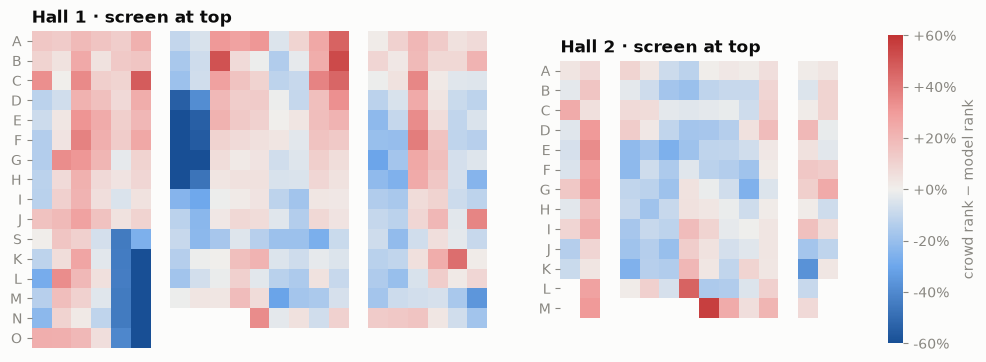

In [10]:
from matplotlib.colors import LinearSegmentedColormap

div = LinearSegmentedColormap.from_list("div", ["#184f95", "#6da7ec", "#f0efec", "#f19c9b", "#c23434"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [23, 14]})
fitted_frames = frames([{"layout": LAYOUT[h], "weights": FIT_W, "target_fov": FIT_FOV} for h in LAYOUT])
for ax, hall, df in zip(axes, LAYOUT, fitted_frames):
    f = standard(df)
    m = measures[measures["hall"] == hall].set_index("seat_id").reindex(f.index)
    diff = m["early_rate"].rank(pct=True) - f["total"].rank(pct=True)
    layout = LAYOUT[hall]
    order = [r["label"] for r in layout["rows"]]
    width = len(layout["rows"][0]["seats"])
    grid = np.full((len(order), width), np.nan)
    for r_i, row in enumerate(layout["rows"]):
        number = 0
        for c, ch in enumerate(row["seats"]):
            if ch == "|":
                continue
            number += 1
            sid = f"{row['label']}{number}"
            if ch == "x" and sid in diff.index:
                grid[r_i, c] = diff[sid]
    im = ax.imshow(grid, cmap=div, vmin=-0.6, vmax=0.6)
    ax.set_yticks(range(len(order)), order)
    ax.set_xticks([])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"{NAME[hall]} · screen at top", loc="left")
cbar = fig.colorbar(im, ax=axes, shrink=0.8, format=lambda v, _: f"{v:+.0%}")
cbar.set_label("crowd rank − model rank")
cbar.outline.set_visible(False)
plt.show()

In [11]:
# Table view: biggest disagreements per hall
for hall, df in zip(LAYOUT, fitted_frames):
    f = standard(df)
    m = measures[measures["hall"] == hall].set_index("seat_id").reindex(f.index)
    diff = (m["early_rate"].rank(pct=True) - f["total"].rank(pct=True)).sort_values()
    print(NAME[hall], "· crowd likes more:", ", ".join(f"{s} {v:+.0%}" for s, v in diff.tail(8)[::-1].items()))
    print(NAME[hall], "· crowd likes less:", ", ".join(f"{s} {v:+.0%}" for s, v in diff.head(8).items()), end="\n\n")

Hall 1 · crowd likes more: B15 +53%, B9 +51%, C6 +48%, A15 +46%, C15 +45%, K20 +43%, F18 +39%, F3 +37%
Hall 1 · crowd likes less: G7 -75%, F7 -74%, L6 -73%, M6 -70%, G8 -68%, K6 -68%, N6 -67%, O6 -65%

Hall 2 · crowd likes more: M7 +56%, L6 +46%, E2 +34%, G2 +31%, M2 +30%, D2 +30%, F2 +28%, L2 +27%
Hall 2 · crowd likes less: K11 -37%, E5 -26%, G9 -25%, K3 -25%, F3 -22%, E3 -22%, J5 -20%, B6 -19%



In [12]:
# Early picks vs overall bookings by seat number (full-width rows), to separate first choice from filling up.
for hall, rows_ in [("hall1", "ABCDEFGHIJSKLM"), ("hall2", "ABCDEFGHIJK")]:
    x = measures[measures["hall"] == hall].assign(row=lambda d: d["seat_id"].str[0], number=lambda d: d["seat_id"].str[1:].astype(int))
    x = x[x["row"].isin(list(rows_))].groupby("number")[["early_rate", "booking_rate"]].mean()
    x.columns = ["early-pick rate", "booking rate"]
    display(x.T.map("{:.0%}".format).rename_axis(f"{NAME[hall]} seat"))

number,1,2,3,4,5,6,7,8,9,10,...,12,13,14,15,16,17,18,19,20,21
Hall 1 seat,,,,,,,,,,,,,,,,,,,,,
early-pick rate,4%,3%,5%,4%,2%,11%,7%,3%,15%,22%,...,12%,8%,11%,29%,6%,2%,4%,4%,2%,5%
booking rate,22%,20%,30%,30%,27%,61%,50%,42%,51%,58%,...,51%,51%,44%,69%,45%,28%,33%,25%,19%,30%


number,1,2,3,4,5,6,7,8,9,10,11,12
Hall 2 seat,,,,,,,,,,,,
early-pick rate,3%,11%,10%,5%,7%,15%,13%,9%,5%,17%,7%,4%
booking rate,24%,49%,46%,36%,38%,47%,45%,43%,37%,58%,36%,28%


The white columns are the aisles. The pattern isn't symmetric, and SeatScore's geometry is symmetric by construction.

* **In Hall 1, early pickers favor the right half of the center block.** Seat 15 is an early pick in 29% of screenings and seats 10–11 in about 21%, while seat 7, just across the left aisle, is an early pick in only 7%. The model rates seats 6–7 as highly as 15–16, which produces the dark blue columns.
* **Seats 6 and 7 are often booked, but they fill late.** Their overall booking rates (61% and 50%) are high, but their early-pick rates (11% and 7%) are not. So the aisle effect in notebook 02 is partly about seats filling up, not first choice.
* **In Hall 2, seat 2 (beside the left aisle) and seats 6–7 are picked earlier than the model expects,** and seats 3–5, 9 and 11 later.
* **Front rows B–C in Hall 1 near the aisles do better than expected,** possibly regular viewers with a favorite seat.

Something about one side of each hall attracts early bookers. It could be the entrance, the booking page's seat map, or habit. It can't be identified from bookings alone.

## Conclusions

1. **SeatScore's default ranking is meaningfully right.** Balanced reaches ρ = 0.58–0.73 against early picks and 0.75 against overall booking rate, using geometry alone.
2. **Fitted weights do better on held-out years** (+0.06 to +0.08). Every near-best fit gives centering and clear view a solid weight, keeps a little aisle access, caps immersion, and prefers a bigger picture than the 40° default (~48°).
3. **The exact weights aren't identifiable.** The factors overlap, so 144 weight sets fit about equally well, and sound and neck comfort can take any value among them. Treat the fit as a direction, not precise numbers.
4. **The results hold up to most dimension estimates.** The exceptions are row S's step, which the data supports, and first-row distance, which trades off against the preferred picture size.
5. **Model changes the data suggests for Version 3:**
   * Split **aisle access** into "beside an inner aisle" and "against the wall". Wall-end seats are the least booked in both halls, yet the model counts them as aisle seats.
   * Base **clear view** on the clearance a seat actually gets, without giving the front row an automatic perfect score.
   * Allow for **left–right asymmetry** (an entrance side, or a learned per-seat offset). Geometry alone can't explain why early bookers favor one side.
   * Learn weights with a **choice model** that uses which seats were still free at each booking, instead of a grid search over seat-level rates.